In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("../data")
MODEL_DIR = Path("../models")

MODEL_DIR.mkdir(exist_ok=True)

# Load datasets from S1
train_df = pd.read_csv(DATA_DIR / "home_advantage_initial.csv")
test_df = pd.read_csv(DATA_DIR / "home_advantage_test.csv")
future_df = pd.read_csv(DATA_DIR / "home_advantage_future.csv")

FEATURES = [
    "league",
    "elo_home",
    "elo_away",
    "crowd_present",
    "stadium_capacity",
    "attendance_pct",
    "travel_distance_km",
    "timezones_crossed",
    "is_derby",
    "venue_familiarity"
]

TARGET = "home_result"

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Future data:", future_df.shape)

print("\nClass distribution (%):")
display(pd.DataFrame({
    "Train": y_train.value_counts(normalize=True) * 100,
    "Test": y_test.value_counts(normalize=True) * 100
}).round(2))

Training: (10000, 10)
Testing: (10000, 10)
Future data: (30000, 11)

Class distribution (%):


,Train,Test
home_result,,
home_win,46.85,46.85
away_win,29.38,29.38
draw,23.77,23.77


Loaded the stratified training and test datasets prepared in S1. The initial training set contains 10,000 matches, while 30,000 records are reserved for future training and 10,000 for independent evaluation.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_features = ["league"]

numerical_features = [
    col for col in FEATURES
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("\nPreprocessor created successfully.")

Categorical features: ['league']
Numerical features: ['elo_home', 'elo_away', 'crowd_present', 'stadium_capacity', 'attendance_pct', 'travel_distance_km', 'timezones_crossed', 'is_derby', 'venue_familiarity']

Preprocessor created successfully.


Created a ColumnTransformer to one-hot encode the categorical league feature and standardize the nine numerical features. Preprocessing will be fitted within the model Pipeline using training data only, preventing test data leakage and allowing the API to accept raw feature values.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

# Train and evaluate
for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro")

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro-F1": macro_f1
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Macro-F1
0,Logistic Regression,0.5047,0.3496
1,Random Forest,0.4846,0.3626


Logistic Regression achieved 50.47% accuracy and 0.3496 macro-F1, while Random Forest achieved 48.46% accuracy and 0.3626 macro-F1.

Both models exceeded the 46.85% majority-class accuracy baseline. Logistic Regression performed better in overall accuracy, whereas Random Forest achieved a slightly higher macro-F1 score. Further class-level evaluation is needed before selecting the final model.


=== Logistic Regression ===
              precision    recall  f1-score   support

    home_win       0.53      0.85      0.65      4685
        draw       0.00      0.00      0.00      2377
    away_win       0.44      0.37      0.40      2938

    accuracy                           0.50     10000
   macro avg       0.32      0.40      0.35     10000
weighted avg       0.38      0.50      0.42     10000



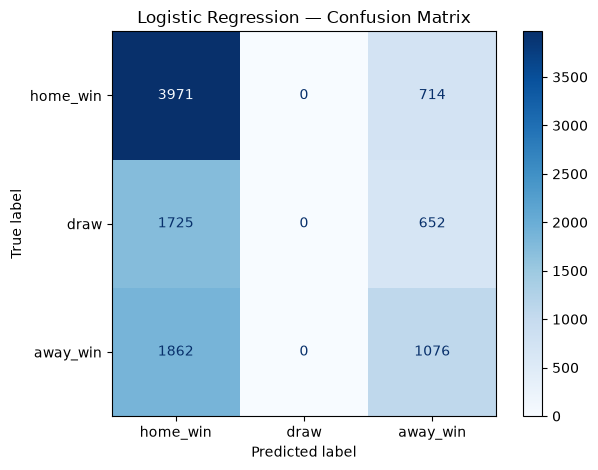


=== Random Forest ===
              precision    recall  f1-score   support

    home_win       0.52      0.80      0.63      4685
        draw       0.26      0.05      0.08      2377
    away_win       0.41      0.34      0.37      2938

    accuracy                           0.48     10000
   macro avg       0.40      0.40      0.36     10000
weighted avg       0.43      0.48      0.43     10000



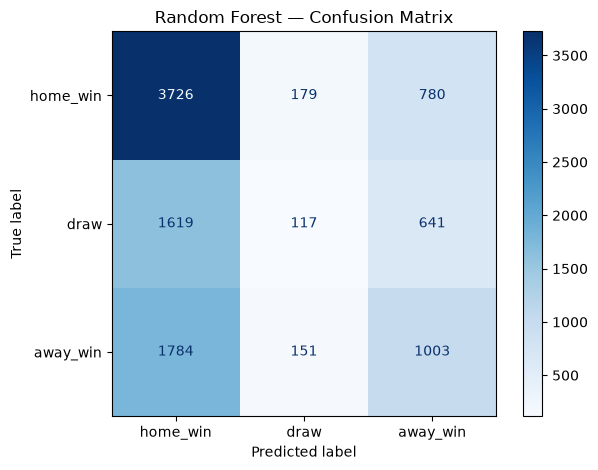

In [4]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_labels = ["home_win", "draw", "away_win"]

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_test)

    print(f"\n=== {name} ===")

    print(classification_report(
        y_test,
        predictions,
        labels=class_labels,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=class_labels,
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()

Logistic Regression achieved 50.47% accuracy but showed a strong bias toward predicting home wins. While home-win recall reached approximately 84.8%, away-win recall was 36.6%, and draw recall was 0%.

The model failed to predict any draws, highlighting the limitations of accuracy as a standalone evaluation metric. Macro-F1 and class-specific recall are therefore important for assessing balanced performance across all three outcomes.

Random Forest achieved 48.46% accuracy and 0.3626 macro-F1. Unlike Logistic Regression, it predicted some draws correctly (117 out of 2,377), but draw recall remained low at approximately 4.9%.

Both models showed a strong preference for predicting home wins. Random Forest achieved slightly better macro-F1, while Logistic Regression maintained higher overall accuracy. These findings highlight the difficulty of predicting minority outcomes.

In [5]:
from sklearn.metrics import log_loss

print("=== INITIAL MODEL LOG LOSS ===")

for name, pipeline in trained_models.items():
    probabilities = pipeline.predict_proba(X_test)

    loss = log_loss(
        y_test,
        probabilities,
        labels=pipeline.classes_
    )

    print(f"{name}: {loss:.4f}")

=== INITIAL MODEL LOG LOSS ===
Logistic Regression: 1.0130
Random Forest: 1.0425


Logistic Regression achieved a lower log loss (1.0130) than Random Forest (1.0425), indicating better probabilistic predictions on the holdout set. Although Logistic Regression also achieved higher accuracy, Random Forest performed slightly better in macro-F1. Further validation-based experiments are required before final model selection.

In [6]:
from sklearn.model_selection import train_test_split

X_dev_train, X_val, y_dev_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Development training:", X_dev_train.shape)
print("Validation:", X_val.shape)

print("\nValidation class distribution (%):")
display(
    (y_val.value_counts(normalize=True) * 100).round(2)
)

Development training: (8000, 10)
Validation: (2000, 10)

Validation class distribution (%):


home_result
home_win    46.85
away_win    29.40
draw        23.75
Name: proportion, dtype: float64

The initial training dataset was split into 8,000 development training and 2,000 validation records using stratified sampling. Class proportions were preserved, allowing model tuning without using the independent holdout set.

In [7]:
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.base import clone

validation_results = []
validation_models = {}

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    pipeline.fit(X_dev_train, y_dev_train)

    predictions = pipeline.predict(X_val)
    probabilities = pipeline.predict_proba(X_val)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro-F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Log Loss": log_loss(
            y_val,
            probabilities,
            labels=pipeline.classes_
        )
    })

    validation_models[name] = pipeline

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(4))

,Model,Accuracy,Macro-F1,Log Loss
0,Logistic Regression,0.5045,0.3484,1.0162
1,Random Forest,0.4855,0.3690,1.0454


On the validation set, Logistic Regression achieved higher accuracy (50.45%) and lower log loss (1.0162), while Random Forest achieved better macro-F1 (0.3690). These results confirm a trade-off between overall predictive performance and class-balanced performance, motivating further model tuning.

In [8]:
# S2.5C — Random Forest Hyperparameter Tuning

rf_configs = {
    "RF Original": {
        "max_depth": None,
        "min_samples_leaf": 1
    },
    "RF Depth 10": {
        "max_depth": 10,
        "min_samples_leaf": 5
    },
    "RF Depth 6": {
        "max_depth": 6,
        "min_samples_leaf": 10
    }
}

rf_results = []
rf_tuned_models = {}

for name, params in rf_configs.items():

    classifier = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        **params
    )

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    pipeline.fit(X_dev_train, y_dev_train)

    predictions = pipeline.predict(X_val)
    probabilities = pipeline.predict_proba(X_val)

    rf_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro-F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Log Loss": log_loss(
            y_val,
            probabilities,
            labels=pipeline.classes_
        )
    })

    rf_tuned_models[name] = pipeline

rf_results_df = pd.DataFrame(rf_results)

display(rf_results_df.round(4))

,Model,Accuracy,Macro-F1,Log Loss
0,RF Original,0.4855,0.3690,1.0454
1,RF Depth 10,0.5025,0.3423,1.0208
2,RF Depth 6,0.5035,0.3294,1.0208


Restricting tree depth improved Random Forest accuracy from 48.55% to 50.35% and reduced log loss from 1.0454 to approximately 1.0208. However, macro-F1 decreased from 0.3690 to 0.3294, indicating a trade-off between overall accuracy and balanced classification performance.

In [9]:
# S2.5D — Logistic Regression Tuning

lr_configs = {
    "LR Original": {
        "class_weight": None,
        "C": 1.0
    },
    "LR Balanced": {
        "class_weight": "balanced",
        "C": 1.0
    },
    "LR Balanced Regularized": {
        "class_weight": "balanced",
        "C": 0.1
    }
}

lr_results = []
lr_tuned_models = {}

for name, params in lr_configs.items():

    classifier = LogisticRegression(
        max_iter=1000,
        random_state=42,
        **params
    )

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    pipeline.fit(X_dev_train, y_dev_train)

    predictions = pipeline.predict(X_val)
    probabilities = pipeline.predict_proba(X_val)

    lr_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro-F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Log Loss": log_loss(
            y_val,
            probabilities,
            labels=pipeline.classes_
        ),
        "Draw Recall": (
            (predictions[y_val == "draw"] == "draw").mean()
        )
    })

    lr_tuned_models[name] = pipeline

lr_results_df = pd.DataFrame(lr_results)

display(lr_results_df.round(4))

,Model,Accuracy,Macro-F1,Log Loss,Draw Recall
0,LR Original,0.5045,0.3484,1.0162,0.0000
1,LR Balanced,0.4355,0.3963,1.0580,0.1832
2,LR Balanced Regularized,0.4355,0.3962,1.0579,0.1832


Applying class_weight="balanced" increased draw recall from 0% to 18.32% and improved macro-F1 from 0.3484 to 0.3963. However, accuracy decreased from 50.45% to 43.55%, while log loss increased from 1.0162 to 1.0580.

Stronger regularization (C=0.1) produced negligible changes. The experiment demonstrates a trade-off between minority-class recognition, overall accuracy, and probability quality.

In [10]:
# S2.5E — Logistic Regression Regularization Tuning

c_values = [0.01, 0.1, 1.0, 10.0]
weight_options = [None, "balanced"]

lr_grid_results = []
lr_grid_models = {}

for weight in weight_options:
    for c in c_values:

        name = f"LR | C={c} | weight={weight}"

        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", LogisticRegression(
                C=c,
                class_weight=weight,
                max_iter=1000,
                random_state=42
            ))
        ])

        pipeline.fit(X_dev_train, y_dev_train)

        predictions = pipeline.predict(X_val)
        probabilities = pipeline.predict_proba(X_val)

        lr_grid_results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro-F1": f1_score(
                y_val, predictions, average="macro"
            ),
            "Log Loss": log_loss(
                y_val,
                probabilities,
                labels=pipeline.classes_
            ),
            "Draw Recall": (
                predictions[y_val == "draw"] == "draw"
            ).mean()
        })

        lr_grid_models[name] = pipeline

lr_grid_df = pd.DataFrame(lr_grid_results)

display(lr_grid_df.round(4))

,Model,Accuracy,Macro-F1,Log Loss,Draw Recall
0,LR | C=0.01 | weight=None,0.5010,0.3439,1.0154,0.0000
1,LR | C=0.1 | weight=None,0.5045,0.3484,1.0161,0.0000
2,LR | C=1.0 | weight=None,0.5045,0.3484,1.0162,0.0000
3,LR | C=10.0 | weight=None,0.5045,0.3484,1.0162,0.0000
4,LR | C=0.01 | weight=balanced,0.4390,0.3989,1.0574,0.1811
5,LR | C=0.1 | weight=balanced,0.4355,0.3962,1.0579,0.1832
6,LR | C=1.0 | weight=balanced,0.4355,0.3963,1.0580,0.1832
7,LR | C=10.0 | weight=balanced,0.4355,0.3963,1.0580,0.1832


Eight Logistic Regression configurations were evaluated using different regularization strengths and class weights.

Changing C had limited impact on performance, while balanced class weighting significantly improved minority-class recognition. The highest macro-F1 (0.3989) was achieved with C=0.01 and balanced weights, compared with 0.3484 for the default model.

However, balancing reduced overall accuracy and increased log loss, demonstrating a trade-off between class-balanced predictions and probability quality.

Logistic Regression with C=0.01 and no class weighting was selected based on the application's priority of probability quality and overall accuracy.

The selected configuration achieved the lowest validation log loss (1.0154) while maintaining competitive accuracy (50.10%). Although balanced weighting improved macro-F1 and draw recall, it reduced accuracy and probability quality.

Limitation: The selected model does not predict draws as the most likely outcome, despite assigning them nonzero probabilities.

In [15]:
# S2.7A — Final Model Training & Export

import joblib
import sklearn
import pickle

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Selected model configuration
final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        C=0.01,
        class_weight=None,
        max_iter=1000,
        random_state=42
    ))
])

# Train using all 10,000 initial records
final_model.fit(X_train, y_train)

# Save complete pipeline
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "model.pkl"

with open(MODEL_DIR / "model.pkl", "wb") as f:
    pickle.dump(final_model, f)

print("=== FINAL MODEL EXPORT ===")
print("Model:", final_model.named_steps["classifier"])
print("Saved to:", model_path.resolve())
print("scikit-learn version:", sklearn.__version__)
print("Classes:", final_model.classes_)

=== FINAL MODEL EXPORT ===
Model: LogisticRegression(C=0.01, max_iter=1000, random_state=42)
Saved to: /Users/baranorek/Desktop/DE-FULL-MODULE/DE-Assignment1-winrate-predictor/models/model.pkl
scikit-learn version: 1.9.1
Classes: ['away_win' 'draw' 'home_win']


In [17]:
# S2.7B — Reload and verify exported model

with open(MODEL_DIR / "model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

# Select one raw match from the holdout dataset
sample = X_test.iloc[[0]]

# Generate prediction and probabilities
prediction = loaded_model.predict(sample)
probabilities = loaded_model.predict_proba(sample)

probability_df = pd.DataFrame(
    probabilities,
    columns=loaded_model.classes_
)

print("=== MODEL VERIFICATION ===")
print("Predicted result:", prediction[0])

print("\nOutcome probabilities:")
display(probability_df.round(4))

print("Probability sum:", probabilities[0].sum())

# Verify model output
assert set(loaded_model.classes_) == {
    "home_win", "draw", "away_win"
}
assert np.isclose(probabilities[0].sum(), 1.0)
assert np.allclose(
    loaded_model.predict_proba(sample),
    final_model.predict_proba(sample)
)

print("\nModel verification passed.")

=== MODEL VERIFICATION ===
Predicted result: home_win

Outcome probabilities:


,away_win,draw,home_win
0,0.0907,0.1698,0.7394


Probability sum: 0.9999999999999999

Model verification passed.


In [18]:
import sklearn
print(sklearn.__version__)


1.9.1
